# FZP cascade comparison using a common focal-spot radius

This notebook recreates the four-panel bandwidth/energy and aspect-ratio/energy comparison between the intermediate-field Fresnel zone-plate cascade and optimized cascade using only the saved sweep data.

For every sweep point, the measured optimized-cascade focal-spot radius is used as the common integration radius for both the optimized cascade and zone-plate cascade while retaining each design's saved incident-area normalization.

The saved focal profiles are cylindrically symmetric, so circular-aperture power can be reconstructed from the stored center-line profiles. No propagation or optimization is rerun.

In [3]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np


In [4]:

matplotlib.rcParams["figure.dpi"] = 200
matplotlib.rcParams.update({"font.size": 24})

cwd = Path.cwd().resolve()
repo_root = next(
    (candidate for candidate in (cwd, *cwd.parents) if (candidate / "paper_data").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Could not locate the repository's paper_data directory.")

path = repo_root / "paper_data"

bw_results = np.load(path / "figS5b_fzp_cascade_bandwidth_energy_sweep_results.npz", allow_pickle=True)
bw_params = np.load(path / "figS5b_fzp_cascade_bandwidth_energy_sweep_params.npy", allow_pickle=True).item()
bw_sweep_arrs = np.load(
    path / "figS5b_fzp_cascade_bandwidth_energy_sweep_sweep_arrays.npy", allow_pickle=True
).item()

ar_results = np.load(path / "figS5b_fzp_cascade_thickness_energy_sweep_results.npz", allow_pickle=True)
ar_params = np.load(path / "figS5b_fzp_cascade_thickness_energy_sweep_params.npy", allow_pickle=True).item()
ar_sweep_arrs = np.load(
    path / "figS5b_fzp_cascade_thickness_energy_sweep_sweep_arrays.npy", allow_pickle=True
).item()

bandwidths = np.asarray(bw_sweep_arrs["bandwidths"], dtype=float)
bw_energies = np.asarray(bw_sweep_arrs["energies"], dtype=float)
thicknesses = np.asarray(ar_sweep_arrs["thicknesses"], dtype=float)
ar_energies = np.asarray(ar_sweep_arrs["energies"], dtype=float)

if not np.array_equal(bw_energies, ar_energies):
    raise ValueError("The bandwidth and aspect-ratio sweeps use different energy axes.")
energies = bw_energies

## Shared-radius efficiency calculation

The saved QDHT intensity maps were generated on an odd-sized radial image and padded on the bottom and right to the even simulation size. The helper below preserves that one-pixel center convention when converting a saved center line into circular-aperture power. The unsaved on-axis radial sample affects only one pixel and is approximated by the nearest saved sample.

In [5]:
def width_central_peak(profile, threshold):
    """Current threshold-crossing definition of the central-peak width."""
    profile = np.asarray(profile)
    center = profile.shape[0] // 2
    center_value = profile[center]
    below_threshold = profile < center_value * threshold

    left_candidates = np.where(below_threshold[:center])[0]
    left = left_candidates[-1] if left_candidates.size else 0

    right_candidates = np.where(below_threshold[center:])[0]
    right = (
        right_candidates[0] + center
        if right_candidates.size
        else profile.shape[0] - 1
    )
    return int(right - left)


def cascade_radius_pixels(profile, params):
    """Reproduce the radius logic in compute_width_and_efficiency_from_2d."""
    radius = width_central_peak(profile, float(params["focusing_threshold"])) // 2
    if radius > int(params["Nx"]) / 10:
        radius = int(
            2 * 1.22 * float(params["min_feature_size"]) / float(params["dx"])
        ) // 2
    return int(radius)


_aperture_count_cache = {}


def circular_aperture_counts(crop_width, radius):
    """Count pixels at each optical radius inside the metric aperture."""
    key = (int(crop_width), int(radius))
    if key not in _aperture_count_cache:
        coordinates = np.arange(crop_width) - crop_width // 2
        yy, xx = np.meshgrid(coordinates, coordinates, indexing="ij")

        # The metric aperture is centered at (0, 0), while the saved QDHT
        # optical center is one pixel toward the upper-left.
        optical_radius = np.rint(np.sqrt((xx + 1) ** 2 + (yy + 1) ** 2)).astype(int)
        aperture = xx**2 + yy**2 <= radius**2
        _aperture_count_cache[key] = np.bincount(optical_radius[aperture])
    return _aperture_count_cache[key]


def circular_power_from_saved_profile(profile, radius, crop_width):
    """Recover circular-aperture power from a saved symmetric center line."""
    profile = np.asarray(profile, dtype=float)
    radial_from_one_pixel = profile[profile.shape[0] // 2 :]

    # The exact on-axis sample was not retained in the center line. It is a
    # single pixel, so use the nearest available radial value.
    radial_values = np.concatenate(
        ([radial_from_one_pixel[0]], radial_from_one_pixel)
    )
    counts = circular_aperture_counts(crop_width, radius)
    return float(np.dot(counts, radial_values[: counts.size]))


def shared_radius_efficiencies(results, params):
    """Compute both cascade efficiencies using the optimized-cascade focal-spot radius."""
    cascade_profiles = np.asarray(results["opt_intensities"], dtype=float)
    fzp_profiles = np.asarray(results["fzp_intensities"], dtype=float)
    if cascade_profiles.shape != fzp_profiles.shape:
        raise ValueError("Optimized and FZP-cascade profile arrays must have the same shape.")

    shape = cascade_profiles.shape[:2]
    crop_width = int(params["crop_width"])
    common_radii = np.empty(shape, dtype=int)
    measured_cascade_radii = np.empty(shape, dtype=int)
    cascade_efficiencies = np.empty(shape, dtype=float)
    fzp_efficiencies = np.empty(shape, dtype=float)

    if "opt_active_radii_pixels" not in results or "fzp_active_radii_pixels" not in results:
        raise KeyError(
            "The saved active-radius arrays are required to retain the original "
            "incident-power normalization."
        )
    cascade_normalization_radii = np.asarray(
        results["opt_active_radii_pixels"], dtype=float
    )
    fzp_normalization_radii = np.asarray(
        results["fzp_active_radii_pixels"], dtype=float
    )

    for index in np.ndindex(shape):
        radius = cascade_radius_pixels(cascade_profiles[index], params)
        measured_cascade_radii[index] = radius
        common_radii[index] = radius

        cascade_power = circular_power_from_saved_profile(
            cascade_profiles[index], radius, crop_width
        )
        fzp_power = circular_power_from_saved_profile(
            fzp_profiles[index], radius, crop_width
        )

        cascade_efficiencies[index] = cascade_power / (
            np.pi * cascade_normalization_radii[index] ** 2
        )
        fzp_efficiencies[index] = fzp_power / (
            np.pi * fzp_normalization_radii[index] ** 2
        )

    return (
        cascade_efficiencies,
        fzp_efficiencies,
        common_radii,
        measured_cascade_radii,
    )


In [6]:
(
    bw_opt_efficiencies_raw,
    bw_fzp_efficiencies_raw,
    bw_common_radii,
    bw_cascade_radii,
) = shared_radius_efficiencies(bw_results, bw_params)
(
    ar_opt_efficiencies_raw,
    ar_fzp_efficiencies_raw,
    ar_common_radii,
    ar_cascade_radii,
) = shared_radius_efficiencies(ar_results, ar_params)

for name, results, recalculated, common_radii, measured_radii in (
    (
        "bandwidth",
        bw_results,
        bw_opt_efficiencies_raw,
        bw_common_radii,
        bw_cascade_radii,
    ),
    (
        "aspect ratio",
        ar_results,
        ar_opt_efficiencies_raw,
        ar_common_radii,
        ar_cascade_radii,
    ),
):
    saved_radii = np.asarray(results["opt_widths"], dtype=int)
    saved_efficiencies = np.asarray(results["opt_efficiencies"], dtype=float)
    print(
        f"{name}: measured-radius mismatches = "
        f"{np.count_nonzero(measured_radii != saved_radii)}; "
        f"common radius range = {common_radii.min()}–{common_radii.max()} pixels; "
        "maximum optimized-cascade efficiency reconstruction difference = "
        f"{np.max(np.abs(recalculated - saved_efficiencies)):.3e}"
    )

# Transpose from saved (sweep variable, energy) order to pcolormesh
# (energy, sweep variable) order.
bw_opt_efficiencies = bw_opt_efficiencies_raw.T
bw_fzp_efficiencies = bw_fzp_efficiencies_raw.T
ar_opt_efficiencies = ar_opt_efficiencies_raw.T
ar_fzp_efficiencies = ar_fzp_efficiencies_raw.T

bandwidth: measured-radius mismatches = 0; common radius range = 6–32 pixels; maximum optimized-cascade efficiency reconstruction difference = 1.147e-03
aspect ratio: measured-radius mismatches = 0; common radius range = 1–291 pixels; maximum optimized-cascade efficiency reconstruction difference = 1.848e-03


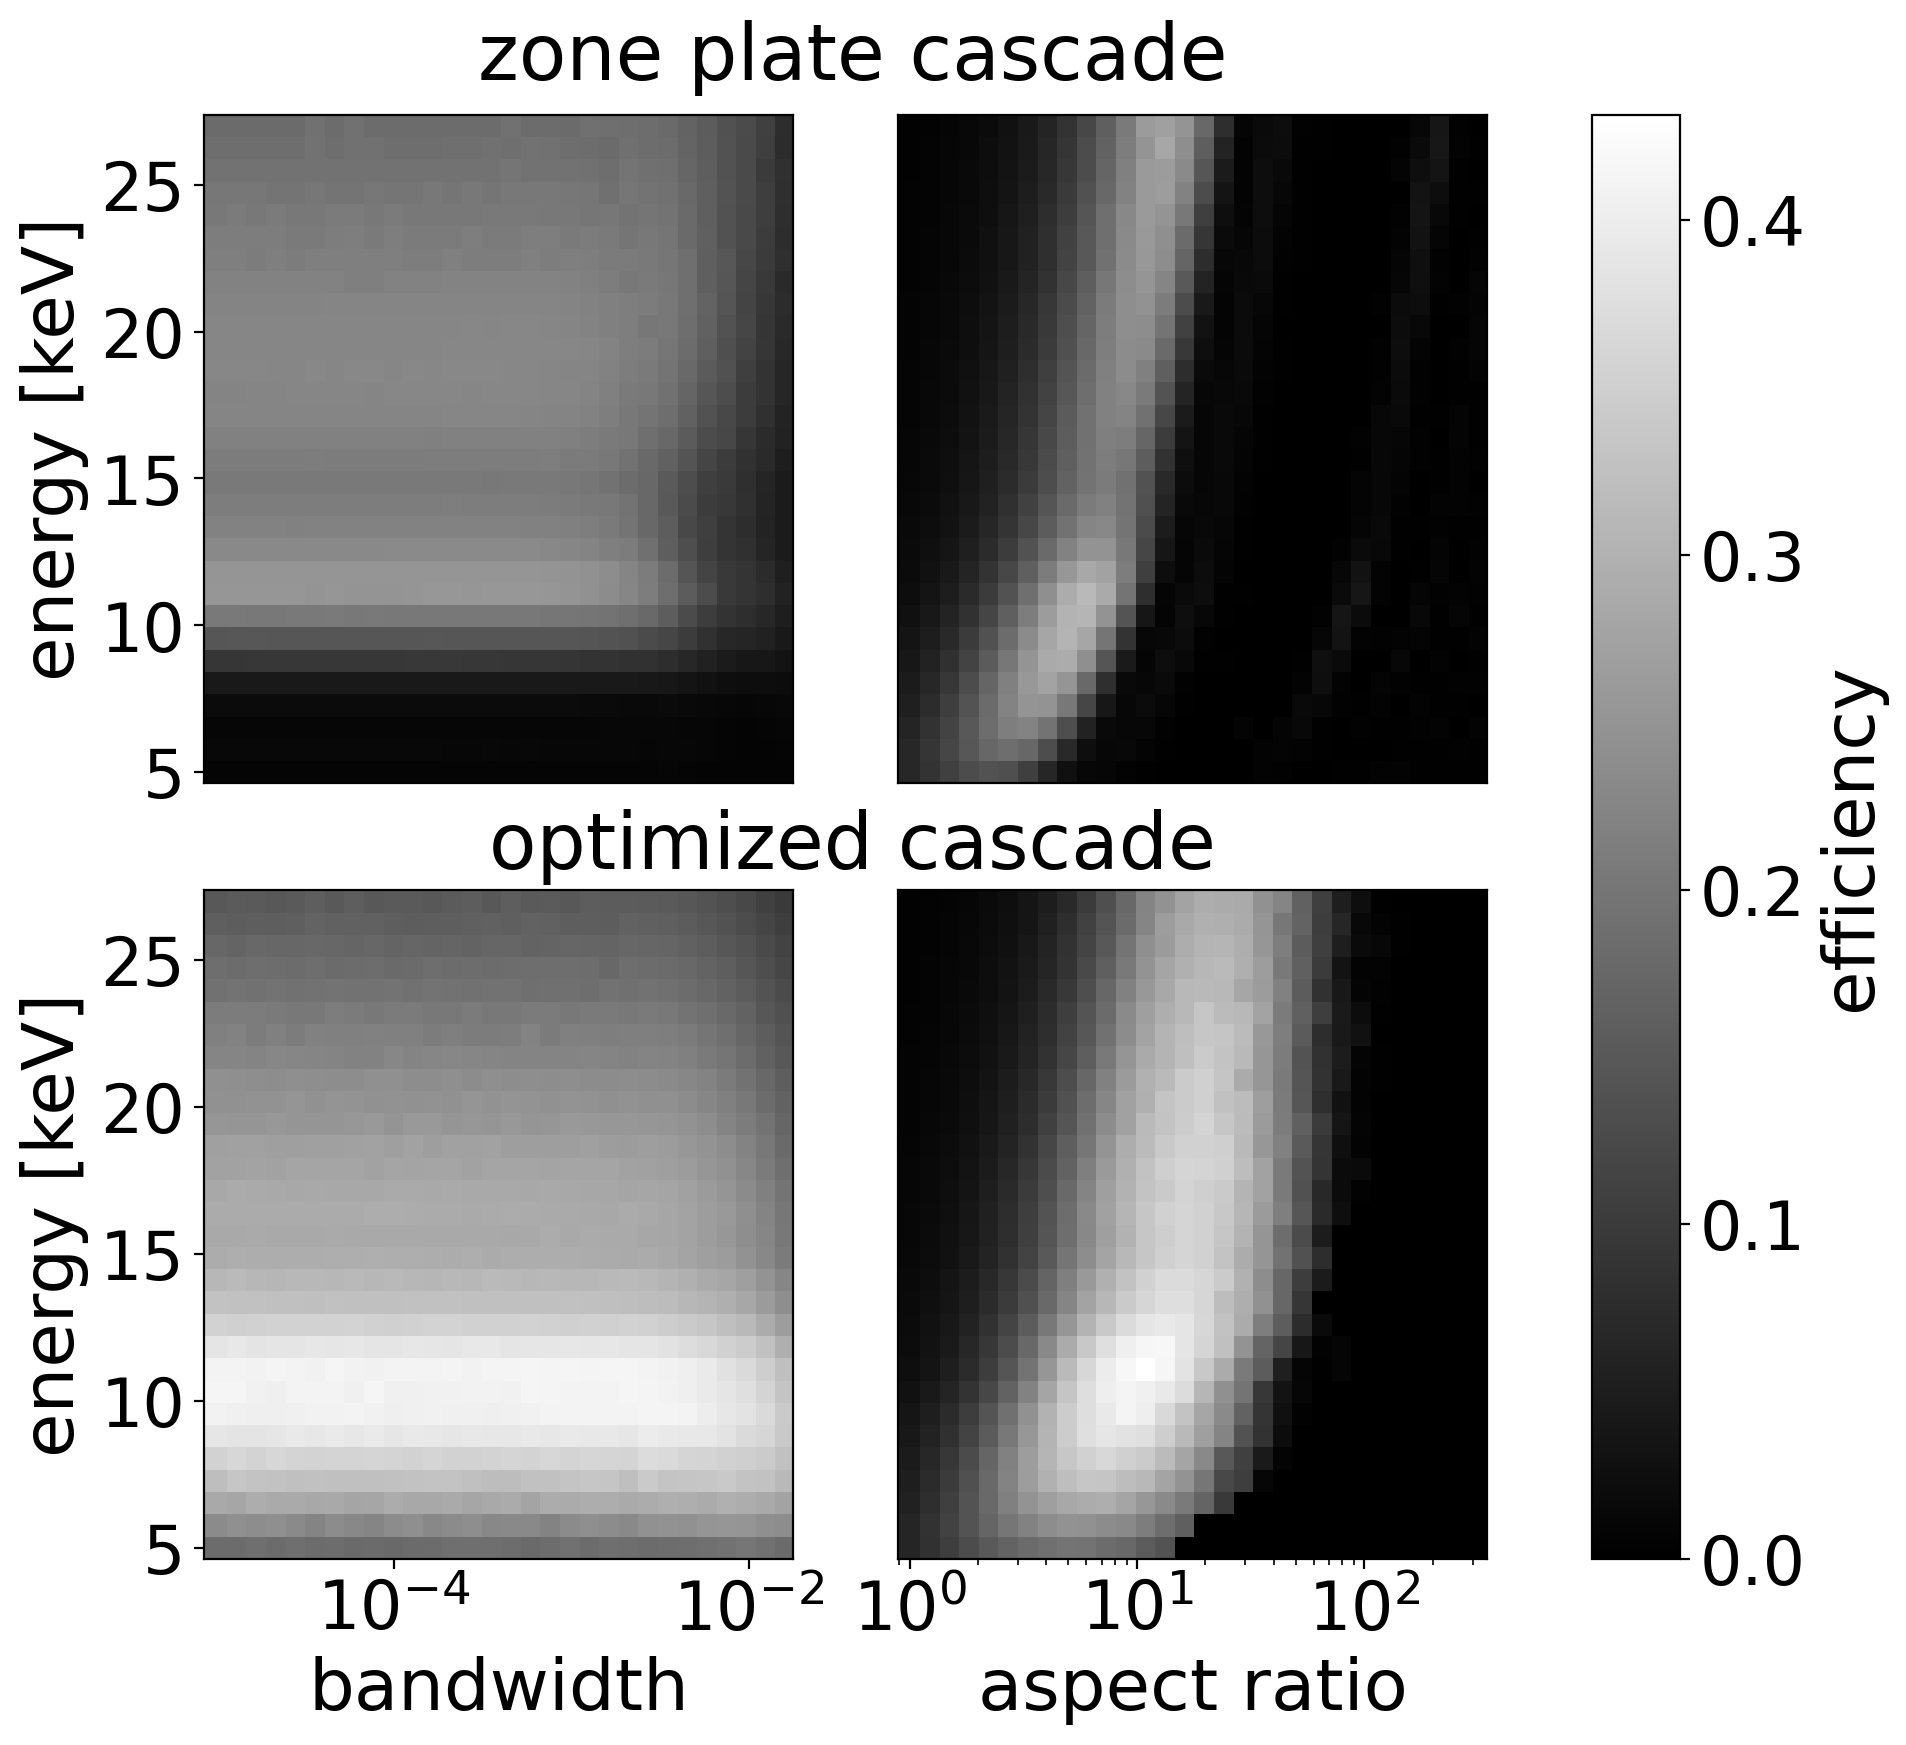

In [7]:
max_eff = max(
    float(np.nanmax(bw_opt_efficiencies)),
    float(np.nanmax(ar_opt_efficiencies)),
)

BW, E = np.meshgrid(bandwidths, energies / 1e3)
T, E_ar = np.meshgrid(
    thicknesses / float(ar_params["min_feature_size"]),
    energies / 1e3,
)

fig = plt.figure(figsize=(9, 9.5))
gs = fig.add_gridspec(
    2,
    3,
    width_ratios=[1, 1, 0.15],
    wspace=0.25,
    hspace=0.16,
    left=0.1,
    right=0.92,
    bottom=0.15,
    top=0.91,
)

ax_tl = fig.add_subplot(gs[0, 0])
ax_tr = fig.add_subplot(gs[0, 1])
ax_bl = fig.add_subplot(gs[1, 0])
ax_br = fig.add_subplot(gs[1, 1])
cax = fig.add_subplot(gs[:, 2])
ax = np.array([[ax_tl, ax_tr], [ax_bl, ax_br]])

ax[0, 0].pcolormesh(
    BW,
    E,
    bw_fzp_efficiencies,
    shading="auto",
    cmap="gray",
    vmin=0.0,
    vmax=max_eff,
)
im = ax[1, 0].pcolormesh(
    BW,
    E,
    bw_opt_efficiencies,
    shading="auto",
    cmap="gray",
    vmin=0.0,
    vmax=max_eff,
)
ax[0, 1].pcolormesh(
    T,
    E_ar,
    ar_fzp_efficiencies,
    shading="auto",
    cmap="gray",
    vmin=0.0,
    vmax=max_eff,
)
im = ax[1, 1].pcolormesh(
    T,
    E_ar,
    ar_opt_efficiencies,
    shading="auto",
    cmap="gray",
    vmin=0.0,
    vmax=max_eff,
)

fig.text(0.46, 0.92, "zone plate cascade", fontsize=28, ha="center", va="bottom")
fig.text(0.46, 0.505, "optimized cascade", fontsize=28, ha="center", va="bottom")

cbar = fig.colorbar(im, cax=cax)
cbar.set_ticks(np.arange(0.0, max_eff + 1e-12, 0.1))
cbar.minorticks_off()
cbar.ax.tick_params(labelsize=24)
cbar.set_label("efficiency", size=26)

for axis in ax.flat:
    axis.set_xscale("log")
    axis.tick_params(labelsize=24)

ax[1, 0].set_xlabel("bandwidth", fontsize=26)
ax[0, 0].set_ylabel("energy [keV]", fontsize=26)
ax[1, 0].set_ylabel("energy [keV]", fontsize=26)
ax[1, 1].set_xlabel("aspect ratio", fontsize=26)

ax[0, 0].xaxis.set_visible(False)
ax[0, 1].xaxis.set_visible(False)
ax[0, 1].yaxis.set_visible(False)
ax[1, 1].yaxis.set_visible(False)

plt.show()